# Flux: USTAR threshold detection for both gas analysers

# About this notebook

At night the measured `NEE` is too low when turbulence is weak, because part of the respired CO2
leaves the site below the sensor or stays in the canopy air. Level 3.3 of the flux chain therefore
removes records with a friction velocity `USTAR` below a threshold, at three thresholds that give
the scenarios `CUT_16`, `CUT_50` and `CUT_84` (see the page on Level 3.3 of the documentation).

This notebook detects the thresholds that FP2026.2 uses, one set per gas analyser, and documents
the checks behind the choice:

1. where the thresholds of FP2026.1 came from, and why they are low;
2. the detection on the current data with the ONEFlux moving point method, and with the other
   methods for comparison;
3. whether the detection finds a known threshold in synthetic data;
4. how night-time `NEE` behaves above the thresholds;
5. why the filter also applies by day;
6. how many records each threshold keeps, and what it does to the night-time respiration;
7. how the thresholds and the annual sums compare with FLUXNET;
8. whether pooling the data of several years, or of several seasons, gives a better threshold, and
   whether the threshold changes from year to year;
9. how night `NEE` compares with the respiration of the daytime partitioning;
10. whether the high night `NEE` at high `USTAR` is CO2 flushed out of the canopy.

The input is `NEE` after Level 3.2, before the USTAR filter, from the flux chains of both analysers.
Level 3.2 does not depend on the thresholds, so the detection can run on the outputs of the chain.

# Main findings

- **FP2026.1.** Its thresholds (0.272, 0.304 and 0.340 m s⁻¹) came from two REddyProc runs with 30
  instead of 20 `USTAR` classes and a shortened plateau test. diive repeats both runs exactly. With the
  REddyProc defaults, the same data give thresholds of about 0.3 to 0.6 m s⁻¹ per year.
- **FP2026.2.** The thresholds come from the ONEFlux moving point method, one set per analyser:
  0.42, 0.52 and 0.65 m s⁻¹ for the LI-7200 and 0.32, 0.44 and 0.55 m s⁻¹ for the LI-7500
  (`CUT_16`, `CUT_50`, `CUT_84`). Of the methods tested, it gives the lowest thresholds; the change
  point method gives medians of 0.59 and 0.64 m s⁻¹.
- **The detection works, but detects too low on noisy data.** In synthetic data it finds a clear
  threshold. With the scatter of the real data and a gradual rise of `NEE`, all methods return a
  threshold below the true one, the moving point method most of all. A detected threshold is
  therefore a lower bound.
- **No plateau.** Night `NEE` keeps rising with `USTAR` up to about 0.9 to 1.0 m s⁻¹, in both analysers
  and in every temperature class.
- **By day.** Daytime records at low `USTAR` show less uptake in sun and more at dawn and dusk than
  well-mixed records under the same conditions, so the filter also applies by day.
- **Cost.** At the FP2026.2 median thresholds about 20 % of the night half-hours stay measured
  (FP2026.1: 28 to 37 %), and the night-time respiration estimated from them is 20 to 27 % higher.
- **FLUXNET.** Over 2005-2024 FLUXNET shows more net uptake than this product, but only because of
  the LI-7500 years, where its self-heating correction makes the nights lower. From 2016, with its
  higher thresholds, it shows less uptake than this product.
- **Constant threshold.** The thresholds of single years differ by no more than the bootstrap
  spread within one year, so a change from year to year cannot be detected.
- **Pooling raises the threshold.** With the data of more years per detection, the moving point
  method returns higher thresholds, and with all years pooled it finds none from April to September.
  Pooling across seasons gives no threshold that agrees between the two analysers.
- **Daytime partitioning.** Night `NEE` reaches the respiration of the daytime method at a `USTAR`
  of about 0.5 to 0.8 m s⁻¹ and exceeds it above. At the FP2026.2 median thresholds the measured
  nights lie 11 % (LI-7200) and 16 % (LI-7500) above it; the two agree at about `CUT_16`.
- **Flushing.** Part of the high night `NEE` at high `USTAR` follows calm hours and is CO2 released
  from the canopy air; the storage term from one height does not capture it.

</br>

# Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
FILES = {
    'IRGA72': dict(nee=r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet",
                   ustar=r"20_L1_FLUXES\IRGA72\99_IRGA72_L1_MERGED_2016-2026.09.parquet"),
    'IRGA75': dict(nee=r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet",
                   ustar=r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet"),
}
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"
ANALYSERS = {'IRGA72': 'LI-7200', 'IRGA75': 'LI-7500'}
COMPLETE_YEARS = {'IRGA72': (2016, 2025), 'IRGA75': (2004, 2017)}  # for per-year counts and sums

# FLUXNET ONEFlux v1.3 for CH-Lae (LI-7500 to 2015, LI-7200 from 2016). Missing values are -9999,
# timestamps are TIMESTAMP_START. The BIF file holds the USTAR thresholds and the REF selection.
FLUXNET_DIR = Path(r"F:\Sync\luhk_work\sites\LAE\Data\Datasets\EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1")
FLUXNET_HH = "EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv"
FLUXNET_YY = "EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv"
FLUXNET_BIF = "EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv"
FLX_MISSING = -9999

# Columns: NEE after Level 3.2 (quality flags 0 and 1, before the USTAR filter), the USTAR of the
# analyser's own Level-1 run, and the meteo of the chain.
NEE, USTAR, ZL = 'NEE_L3.1_L3.2_QCF', 'USTAR', 'ZL'
TA, SW_IN, VPD = 'TA_T1_47_1_HOMOGENIZED_gfXG', 'SW_IN_T1_47_1_gfXG', 'VPD_T1_47_1_HOMOGENIZED'
NIGHTTIME = 'NIGHTTIME'  # night flag of the chain
NIGHT_SW_IN = 10  # W m-2, night as the detection defines it

# Detection of FP2026.2: ONEFlux moving point method (Papale et al. 2006) in diive, 100 bootstrap
# draws per year, CUT from the draws of all years. Only the moving point method is used: of the
# methods that detect a threshold at this site, it gives the lowest one.
DETECTION = dict(mode='oneflux_mp', n_iter=100, random_state=42, percentiles=(16, 50, 84))

# The thresholds written into the chain notebooks (USTAR_THRESHOLDS in 05_FPPC_*_NEE), CUT_16/50/84
# in m s-1. They come from the detection below; the integrity check compares them with it.
USTAR_THRESHOLDS = {'IRGA72': [0.415500, 0.523400, 0.645100],
                    'IRGA75': [0.317700, 0.438900, 0.552800]}
THRESHOLD_TOLERANCE = 0.005  # m s-1

# FP2026.1: one set for both analysers, from two REddyProc runs in R (L3.3 page of the docs).
USTAR_THRESHOLDS_FP1 = [0.271619922, 0.303628125, 0.339684084]
_old = r"30_FLUX_POST-PROCESSING_CHAIN"
FP1_RUNS = {
    'IRGA72': dict(input=_old + r"\IRGA72\USTAR_DETECTION_2016-2024\14_IRGA72_SUBSET_NEE_QCF11_2016-2024.csv",
                   result=_old + r"\IRGA72\USTAR_DETECTION_2016-2024\16_USTAR-THRESHOLDS_NEE_QCF11_IRGA72_2016-2024_RP-20251113112030.csv",
                   first='2016-01-01 00:30', last='2025-01-01 00:00', ustar_classes=30, plateau_fwd=9),
    'IRGA75': dict(input=_old + r"\IRGA75\USTAR_DETECTION_2005-2019\04_IRGA75_SUBSET_NEE_QCF10_2005-2019.csv",
                   result=_old + r"\IRGA75\USTAR_DETECTION_2005-2019\06_IRGA75_USTAR-THRESHOLDS_NEE_QCF10_2005-2019_RP-20251113130417.csv",
                   first='2005-01-01 00:30', last='2020-01-01 00:00', ustar_classes=30, plateau_fwd=8),
}

# Synthetic test: true respiration with a known USTAR effect, on the real USTAR, TA and gaps of the
# LI-7200 years.
SYNTH_ANALYSER = 'IRGA72'
SYNTH_E0, SYNTH_RREF = 150.0, 3.5  # K, umol m-2 s-1 at 10 degC

# Thresholds compared for the records kept and the respiration.
COMPARE = {'FP2026.1 CUT_50': USTAR_THRESHOLDS_FP1[1], '0.40': 0.40, '0.70': 0.70}
TREF, T0 = 15.0, -46.02  # Lloyd-Taylor, as the night-time partitioning of ONEFlux
GC = 12.011e-6 * 1800  # umol m-2 s-1 in one half-hour -> gC m-2

# Pooling (section 8): the moving point method on the data of several years, or of all years with
# other seasons. Seasons are lists of months; ONEFlux uses calendar quarters.
SEASONS = {'quarters': [[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]],
           'leaf-off, leaf-on': [[11, 12, 1, 2, 3, 4], [5, 6, 7, 8, 9, 10]],
           'one season': [list(range(1, 13))]}
POOL_YEARS = (1, 3, 5)  # years of data per detection, centred on the year
POOL_DRAWS = 100  # bootstrap draws per detection

# Daytime-method RECO (section 9) and the flush test (section 10)
RECO_DT = 'RECO_DT_OF_CUT_50'  # daytime partitioning of the chain (Lasslop et al. 2010)
STORAGE = 'SC_SINGLE_gfRMED_L3.1'  # storage term of the chain, from the concentration at one height
LEAF_ON = [5, 6, 7, 8, 9, 10]  # months
PREVIOUS_HOURS = 3  # window for the mean USTAR before a record

# Imports

In [2]:
import importlib.metadata
import textwrap
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from diive.flux.lowres.ustar_detection import UstarThresholdDetection
from diive.flux.lowres.ustar_mp_detection import UstarMovingPointDetection
from diive.flux.lowres.ustar_cp_detection import UstarChangePointDetection
from diive.flux.lowres.ustar_reddyproc_detection import UstarReddyProcDetection

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=RuntimeWarning)
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
for _p in ('diive', 'pandas', 'numpy'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-11-01 13:35:04
diive version: v0.93.0
pandas version: v3.0.3
numpy version: v2.4.6


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.2f}", subset=None, cmap="RdBu_r", center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values."""
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {c: fmt.get(c, "{:.2f}") for c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None or not numeric:
        return styler
    values = data[subset] if subset is not None else data[numeric]
    limits = {}
    if center:
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, text_color_threshold=0.4, **limits)


def full_years(df):
    """`df` on the complete half-hourly grid of its calendar years, as the detection expects."""
    grid = pd.date_range(f"{df.index[0].year}-01-01 00:15", f"{df.index[-1].year}-12-31 23:45",
                         freq='30min', name='TIMESTAMP_MIDDLE')
    out = df.reindex(grid)
    out.index.freq = '30min'
    return out


DET_COLS = dict(nee_col=NEE, ta_col=TA, ustar_col=USTAR, swin_col=SW_IN)


def lloyd_taylor(t, e0):
    return np.exp(e0 * (1.0 / (TREF - T0) - 1.0 / (t - T0)))


def reco_estimate(frame, nee_night, e0_by_year):
    """Night-time respiration at every half-hour: reference respiration per day from the measured
    night NEE within +-7 days (widened to 15, 30 and 60 days for at least 10 records), times
    Lloyd-Taylor with the E0 of the year from the chain's night-time partitioning."""
    out = pd.Series(np.nan, index=frame.index)
    day_no = (frame.index - frame.index[0]).days
    for yr in np.unique(frame.index.year):
        k = frame.index.year == yr
        y, t, dd = nee_night[k], frame.loc[k, TA], day_no[k]
        ok = y.notna().to_numpy()
        yy, ff, ddd = y.to_numpy()[ok], lloyd_taylor(t, e0_by_year[yr]).to_numpy()[ok], dd[ok]
        rref = {}
        for day in np.unique(dd):
            for half in (7, 15, 30, 60):
                w = np.abs(ddd - day) <= half
                if w.sum() >= 10:
                    rref[day] = (yy[w] * ff[w]).sum() / (ff[w] ** 2).sum()
                    break
        out[k] = pd.Series(dd).map(rref).to_numpy(dtype=float) * lloyd_taylor(t, e0_by_year[yr]).to_numpy()
    return out

</br>

# Load data

In [4]:
_met = pd.read_parquet(DATADIR / FILE_METEO, columns=[TA, SW_IN, VPD])
_paths = {}
data = {}
for _a, _f in FILES.items():
    _n = pd.read_parquet(DATADIR / _f['nee'], columns=[NEE, NIGHTTIME, 'E0_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50',
                                                        'NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED',
                                                        RECO_DT, STORAGE])
    _u = pd.read_parquet(DATADIR / _f['ustar'], columns=[USTAR, ZL])
    data[_a] = full_years(_n.join(_u).join(_met))
    _paths[f"{_a} NEE (05)"] = DATADIR / _f['nee']
    _paths[f"{_a} USTAR"] = DATADIR / _f['ustar']
    print(f"{_a}: {data[_a].index[0]} to {data[_a].index[-1]}, "
          f"{(data[_a][NEE].notna() & (data[_a][SW_IN] < NIGHT_SW_IN)).sum():,} night records with NEE")
_paths['meteo, merged'] = DATADIR / FILE_METEO
for _k, _fn in (('FLUXNET, half-hourly', FLUXNET_HH), ('FLUXNET, yearly', FLUXNET_YY), ('FLUXNET, BIF', FLUXNET_BIF)):
    _paths[_k] = FLUXNET_DIR / _fn

IRGA72: 2016-01-01 00:15:00 to 2026-12-31 23:45:00, 58,827 night records with NEE
IRGA75: 2004-01-01 00:15:00 to 2017-12-31 23:45:00, 60,509 night records with NEE


## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({'file': [p.name for p in _paths.values()],
                        'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _paths.values()]},
                       index=list(_paths))
display(styled(_inputs, caption="the input files with their modification time. The thresholds in this notebook "
                                "belong to the runs of these dates", cmap=None))

Table — the input files with their modification time. The thresholds in this notebook belong to the
runs of these dates



,file,modified
IRGA72 NEE (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-31 21:03
IRGA72 USTAR,99_IRGA72_L1_MERGED_2016-2026.09.parquet,2026-10-25 02:04
IRGA75 NEE (05),05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-31 17:24
IRGA75 USTAR,01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet,2026-10-30 00:49
"meteo, merged",99_METEO_MERGED_2004-2026.09.parquet,2026-10-29 21:02
"FLUXNET, half-hourly",EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, yearly",EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, BIF",EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv,2025-12-23 07:05


## Integrity checks

In [6]:
_issues = []
for _a, _d in data.items():
    if _d.index.duplicated().any():
        _issues.append(f"{_a}: duplicate timestamps")
    if _d[USTAR].lt(0).any():
        _issues.append(f"{_a}: negative USTAR")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

Integrity checks passed.


</br>

# 1. The thresholds of FP2026.1

FP2026.1 used one set of thresholds for both analysers, from two runs of the R package REddyProc:
one on the LI-7200 data of 2016-2024, one on the LI-7500 data of 2005-2019. Both runs changed two
settings from their defaults: 30 instead of 20 `USTAR` classes per temperature class, and a plateau
test over 9 or 8 following classes instead of 10. diive reproduces REddyProc 1.3.4 exactly, also
with these settings, so the runs can be repeated here on their original input files.

## 📋 Table: FP2026.1 detection repeated, with the settings of the time and with the defaults

In [7]:
_rows = []
fp1 = {}
for _a, _r in FP1_RUNS.items():
    _in = pd.read_csv(DATADIR / _r['input'], parse_dates=['TIMESTAMP_END'], index_col='TIMESTAMP_END')
    _in = _in.loc[_r['first']:_r['last']]
    _cols = dict(nee_col='NEE_L3.1_L3.2_QCF', ta_col='TA_T1_47_1_gfXG', ustar_col='USTAR', swin_col='SW_IN_T1_47_1_gfXG')
    _old = pd.read_csv(DATADIR / _r['result'])
    _old_year = _old[_old['aggregationMode'] == 'year'].set_index('seasonYear')['uStar']
    _then = UstarReddyProcDetection(_in, **_cols, ustar_classes=_r['ustar_classes'], plateau_fwd=_r['plateau_fwd'], verbose=0).run()
    _default = UstarReddyProcDetection(_in, **_cols, verbose=0).run()
    _y_then = _then.seasons_.groupby('season_year')['ustar'].max()
    _y_def = _default.seasons_.groupby('season_year')['ustar'].max()
    fp1[_a] = dict(then=_y_then, default=_y_def, r=_old_year)
    for _y in _old_year.index:
        _rows.append({'analyser': ANALYSERS[_a], 'year': int(_y), 'R run of 2025': _old_year[_y],
                      'diive, settings of the R run': _y_then.get(_y, np.nan),
                      'diive, REddyProc defaults': _y_def.get(_y, np.nan)})
fp1_table = pd.DataFrame(_rows).set_index(['analyser', 'year'])
fp1_table['difference to R'] = fp1_table['diive, settings of the R run'] - fp1_table['R run of 2025']
display(styled(fp1_table, caption="yearly USTAR thresholds (m s-1) of the FP2026.1 detection: as written by the "
                                  "R run, repeated with diive with the same settings (30 USTAR classes, plateau "
                                  "over 9 or 8 classes), and with the REddyProc defaults (20 classes, plateau over 10)",
               fmt={'difference to R': "{:.6f}", 'R run of 2025': "{:.4f}", 'diive, settings of the R run': "{:.4f}",
                    'diive, REddyProc defaults': "{:.4f}"}, cmap=None))

Table — yearly USTAR thresholds (m s-1) of the FP2026.1 detection: as written by the R run, repeated
with diive with the same settings (30 USTAR classes, plateau over 9 or 8 classes), and with the
REddyProc defaults (20 classes, plateau over 10)



diive repeats both runs exactly, year by year. With the REddyProc defaults, the same inputs give
higher thresholds in almost every year. The low thresholds of FP2026.1 therefore follow from the two
changed settings. The plateau test compares a class with a fixed number of following classes, and
with 30 classes these cover a narrower range of `USTAR`. Night `NEE` that still rises slowly across
that range then passes the test as a plateau. REddyProc itself warns when `UstarClasses` is changed
from its default.

</br>

# 2. Detection on the current data

The moving point method (ONEFlux `ustar_mp`, Papale et al. 2006) sorts each season's night
records into 7 temperature classes and each of those into 20 `USTAR` classes. The threshold is
the first class whose `NEE` reaches the mean `NEE` of the following classes, the plateau. The
change point method (ONEFlux `ustar_cp`, Barr et al. 2013) fits a line that becomes flat at a
change point. ONEFlux pools both; REddyProc uses its own variant of the moving point method. All
three are run here, each with its bootstrap, on the same input.

In [8]:
detections = {}
for _a, _d in data.items():
    for _mode in ('oneflux_mp', 'oneflux_cp', 'oneflux', 'reddyproc'):
        _t = time.time()
        _kw = dict(DETECTION, mode=_mode)
        if _mode == 'reddyproc':
            _kw.update(n_iter=None, percentiles=None)  # REddyProc's own: 200 draws, 5/50/95
        _det = UstarThresholdDetection(_d, n_jobs=-1, verbose=0, **DET_COLS, **_kw)
        _det.run()
        detections[(_a, _mode)] = _det
        print(f"{ANALYSERS[_a]}, {_mode}: {time.time() - _t:.0f} s")

LI-7200, oneflux_mp: 6 s


LI-7200, oneflux_cp: 9 s


LI-7200, oneflux: 7 s


LI-7200, reddyproc: 5 s


LI-7500, oneflux_mp: 1 s


LI-7500, oneflux_cp: 3 s


LI-7500, oneflux: 3 s


LI-7500, reddyproc: 6 s


## 📋 Table: CUT thresholds per analyser and method

In [9]:
_rows = {}
for (_a, _mode), _det in detections.items():
    _cut = _det.get_cut_threshold()
    _v = list(_cut.values())
    _rows[(ANALYSERS[_a], _mode)] = {'low (p16 or p5)': _v[0], 'median': _v[1], 'high (p84 or p95)': _v[-1],
                                     'years without a threshold': sum(1 for f in _det.failures_.values() if f)}
cut_table = pd.DataFrame(_rows).T
cut_table.index.names = ['analyser', 'method']
display(styled(cut_table, caption="CUT thresholds (m s-1) from the bootstrap draws of all years, per analyser and "
                                  "method: the 16th, 50th and 84th percentiles (REddyProc: 5th, 50th, 95th). FP2026.1 "
                                  "used 0.272, 0.304 and 0.340 for both analysers",
               fmt={'years without a threshold': "{:.0f}"}, cmap=None))

Table — CUT thresholds (m s-1) from the bootstrap draws of all years, per analyser and method: the
16th, 50th and 84th percentiles (REddyProc: 5th, 50th, 95th). FP2026.1 used 0.272, 0.304 and 0.340
for both analysers



## 📋 Table: median threshold per year, moving point method

In [10]:
_vut = {ANALYSERS[_a]: detections[(_a, 'oneflux_mp')].get_vut_thresholds()['p50'] for _a in data}
_vut_cp = {f"{ANALYSERS[_a]}, change point": detections[(_a, 'oneflux_cp')].get_vut_thresholds()['p50'] for _a in data}
vut_table = pd.DataFrame({**_vut, **_vut_cp})
display(styled(vut_table, caption="median USTAR threshold (m s-1) per year from the draws of the year and its two "
                                  "neighbours (VUT), moving point method, with the change point method for comparison",
               cmap=None))

Table — median USTAR threshold (m s-1) per year from the draws of the year and its two neighbours
(VUT), moving point method, with the change point method for comparison



,LI-7200,LI-7500,"LI-7200, change point","LI-7500, change point"
year,,,,
2004,-,0.44,-,0.58
2005,-,0.42,-,0.60
2006,-,0.43,-,0.62
2007,-,0.49,-,0.65
2008,-,0.49,-,0.63
2009,-,0.44,-,0.61
2010,-,0.41,-,0.61
2011,-,0.41,-,0.65
2012,-,0.42,-,0.68


## 📋 Table: thresholds of the chain against the detection

In [11]:
_rows = {}
for _a in data:
    _cut = list(detections[(_a, 'oneflux_mp')].get_cut_threshold().values())
    for _lab, _det_v, _used in zip(('CUT_16', 'CUT_50', 'CUT_84'), _cut, USTAR_THRESHOLDS[_a]):
        _rows[(ANALYSERS[_a], _lab)] = {'detected': _det_v, 'in the chain': _used, 'difference': _used - _det_v}
check_table = pd.DataFrame(_rows).T
display(styled(check_table, caption=f"USTAR thresholds (m s-1) of FP2026.2 as written into the chain notebooks, "
                                    f"against this run of the moving point method. A difference above "
                                    f"{THRESHOLD_TOLERANCE} m s-1 means the chain's values need updating",
               fmt={'difference': "{:+.4f}", 'detected': "{:.4f}", 'in the chain': "{:.4f}"}, cmap=None))
_off = check_table['difference'].abs() > THRESHOLD_TOLERANCE
if _off.any():
    print("WARNING: the thresholds of the chain differ from this detection: " + ", ".join(f"{a} {c}" for a, c in check_table.index[_off]))
else:
    print(f"The thresholds of the chain agree with this detection within {THRESHOLD_TOLERANCE} m s-1.")

Table — USTAR thresholds (m s-1) of FP2026.2 as written into the chain notebooks, against this run
of the moving point method. A difference above 0.005 m s-1 means the chain's values need updating



The thresholds of the chain agree with this detection within 0.005 m s-1.


For both analysers the moving point method gives the lowest thresholds of the ONEFlux methods, and
the change point method the highest. The LI-7500 thresholds are lower than those of the LI-7200. In
the overlap 2016-2017 the yearly values of the two analysers differ by less than 0.1 m s⁻¹. FP2026.2
uses the constant thresholds (CUT) of the moving point method, one set per analyser.

</br>

# 3. Does the detection find a known threshold?

Synthetic night `NEE` with a known effect of `USTAR` is placed on the real `USTAR`, temperature and
gaps of the LI-7200 years: a respiration that follows temperature, times a factor that rises with
`USTAR` up to a given value and stays at 1 above it. Each method should return that value. The
test is run without noise and with noise of the size found in the real night `NEE` (the standard
deviation within cells of the same month, 2 K of temperature and 0.1 m s-1 of `USTAR`, above
0.6 m s-1). The methods run on the original records, without the bootstrap.

In [12]:
_d = data[SYNTH_ANALYSER]
_s = _d[(_d[SW_IN] < NIGHT_SW_IN) & (_d[USTAR] > 0.6)].dropna(subset=[NEE, TA, USTAR])
SYNTH_NOISE = float(_s.groupby([_s.index.month, _s[TA] // 2, _s[USTAR] // 0.1])[NEE].std().median())
print(f"Scatter of the real night NEE: {SYNTH_NOISE:.2f} umol m-2 s-1")
_resp = SYNTH_RREF * np.exp(SYNTH_E0 * (1 / (10 + 46.02) - 1 / (_d[TA] + 46.02)))
_u = _d[USTAR].clip(lower=0)
SCENARIOS = {
    'plateau from 0.3': np.minimum(1, _u / 0.3),
    'plateau from 0.6': np.minimum(1, _u / 0.6),
    'plateau from 0.9': np.minimum(1, _u / 0.9),
    'gradual, plateau from 0.9': np.minimum(1, np.sqrt(_u / 0.9)),
    'rising up to 1.2': np.minimum(1, 0.3 + 0.7 * _u / 1.2),
    'no USTAR effect': pd.Series(1.0, index=_d.index),
}
_rng = np.random.default_rng(1)
_rows = []
for _noise in (0.0, SYNTH_NOISE):
    for _name, _f in SCENARIOS.items():
        _syn = _d[[TA, USTAR, SW_IN]].copy()
        _syn[NEE] = (_resp * _f + _rng.normal(0, _noise, len(_syn))).where(_d[NEE].notna())
        _mp, _cp = [], []
        for _y in np.unique(_syn.index.year):
            _dy = _syn.loc[str(_y)]
            if (_dy[NEE].notna() & (_dy[SW_IN] < NIGHT_SW_IN)).sum() < 1000:
                continue
            _m = UstarMovingPointDetection(_dy, verbose=0, **DET_COLS)
            _m.detect()
            _mp.append(_m.annual_thresholds_['threshold'])
            _c = UstarChangePointDetection(_dy, verbose=0, **DET_COLS)
            _c.detect()
            _cp.append(np.nan if _c.detect_failure_ else _c.annual_threshold_)
        _rp = UstarReddyProcDetection(_syn, verbose=0, **DET_COLS).run()
        _rows.append({'noise': 'none' if _noise == 0 else 'as in the data', 'synthetic USTAR effect': _name,
                      'moving point': np.nanmedian(_mp), 'change point': np.nanmedian(_cp) if np.isfinite(_cp).any() else np.nan,
                      'REddyProc': float(_rp.seasons_.groupby('season_year')['ustar'].max().median())})
synth_table = pd.DataFrame(_rows).set_index(['noise', 'synthetic USTAR effect'])

Scatter of the real night NEE: 3.16 umol m-2 s-1


## 📋 Table: thresholds detected in synthetic data

In [13]:
display(styled(synth_table, caption="median over the years of the annual threshold (m s-1) that each method detects "
                                    "in synthetic night NEE with a known USTAR effect, without noise and with the "
                                    "scatter of the real data. '-': no threshold detected", cmap=None))

Table — median over the years of the annual threshold (m s-1) that each method detects in synthetic
night NEE with a known USTAR effect, without noise and with the scatter of the real data. '-': no
threshold detected



Without noise, all three methods find a clear threshold at 0.3 or 0.6 m s⁻¹. The ONEFlux moving
point method reports it somewhat high, because it returns the mean `USTAR` of a class. With the
scatter of the real data, the methods detect too low when the true threshold is high or the rise is
gradual: a plateau from 0.9 m s⁻¹ comes out at 0.36 to 0.71 m s⁻¹, and a flux that keeps rising up
to 1.2 m s⁻¹ at 0.25 to 0.63 m s⁻¹. The change point method is the least affected. Without any
effect of `USTAR`, the moving point methods still return about 0.2 m s⁻¹, as their design implies,
while the change point method correctly returns none. Where night `NEE` rises gradually, a detected
threshold is therefore a lower bound.

</br>

# 4. Night-time NEE above the thresholds

If a threshold marks the start of a plateau, night `NEE` at the same temperature should no longer
rise with `USTAR` above it.

In [14]:
_ubins = np.r_[0, np.arange(0.1, 1.21, 0.1), 3]
_tbins = [-20, 5, 10, 15, 20, 35]
curves, curve_n = {}, {}
for _a, _d in data.items():
    _s = _d[_d[SW_IN] < NIGHT_SW_IN].dropna(subset=[NEE, USTAR, TA])
    _ub = pd.cut(_s[USTAR], _ubins)
    curves[_a] = _s.pivot_table(index=_ub, columns=pd.cut(_s[TA], _tbins), values=NEE, aggfunc='mean', observed=True)
    curve_n[_a] = _s.groupby(_ub, observed=True).size()

## 📋 Table: mean night NEE by USTAR and air temperature

In [15]:
_t = pd.concat({ANALYSERS[_a]: curves[_a].assign(n=curve_n[_a]) for _a in data}, axis=1)
_t.index = [f"{i.left:.1f}-{i.right:.1f}" for i in _t.index]
_t.index.name = 'USTAR (m s-1)'
_t.columns = [f"{a}, {c}" if c == 'n' else f"{a}, TA {c.left:.0f} to {c.right:.0f} °C" for a, c in _t.columns]
display(styled(_t, caption="mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) per USTAR bin and "
                           "air temperature class, and the number of records per USTAR bin",
               fmt={c: ("{:.0f}" if c.endswith(', n') else "{:.2f}") for c in _t.columns}, cmap=None))

Table — mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) per USTAR bin and air
temperature class, and the number of records per USTAR bin



,"LI-7200, TA -20 to 5 °C","LI-7200, TA 5 to 10 °C","LI-7200, TA 10 to 15 °C","LI-7200, TA 15 to 20 °C","LI-7200, TA 20 to 35 °C","LI-7200, n","LI-7500, TA -20 to 5 °C","LI-7500, TA 5 to 10 °C","LI-7500, TA 10 to 15 °C","LI-7500, TA 15 to 20 °C","LI-7500, TA 20 to 35 °C","LI-7500, n"
USTAR (m s-1),,,,,,,,,,,,
0.0-0.1,0.53,0.35,0.59,0.59,0.42,2734,-0.36,0.17,0.24,0.37,0.39,3191
0.1-0.2,0.92,1.02,0.99,0.89,0.76,10101,0.11,0.29,0.57,0.64,0.71,11195
0.2-0.3,1.49,1.87,1.83,1.42,1.28,9529,0.34,0.83,1.19,1.40,1.17,10288
0.3-0.4,2.01,2.60,2.97,2.50,1.72,7970,1.02,1.59,2.24,2.87,2.45,8281
0.4-0.5,2.39,3.20,4.01,3.59,3.18,6801,1.53,2.56,3.35,4.22,3.59,7133
0.5-0.6,2.81,3.84,4.88,4.76,4.33,5594,1.78,3.16,4.46,5.01,5.03,6082
0.6-0.7,2.92,3.96,5.04,6.25,4.97,4536,2.32,3.84,4.82,6.46,5.74,4574
0.7-0.8,3.05,4.31,5.48,6.81,6.19,3280,2.32,4.19,5.64,7.05,7.48,3189
0.8-0.9,3.19,4.46,6.25,7.35,7.63,2529,2.56,4.76,6.47,8.05,8.62,2226


## 📊 Plot: night NEE against USTAR

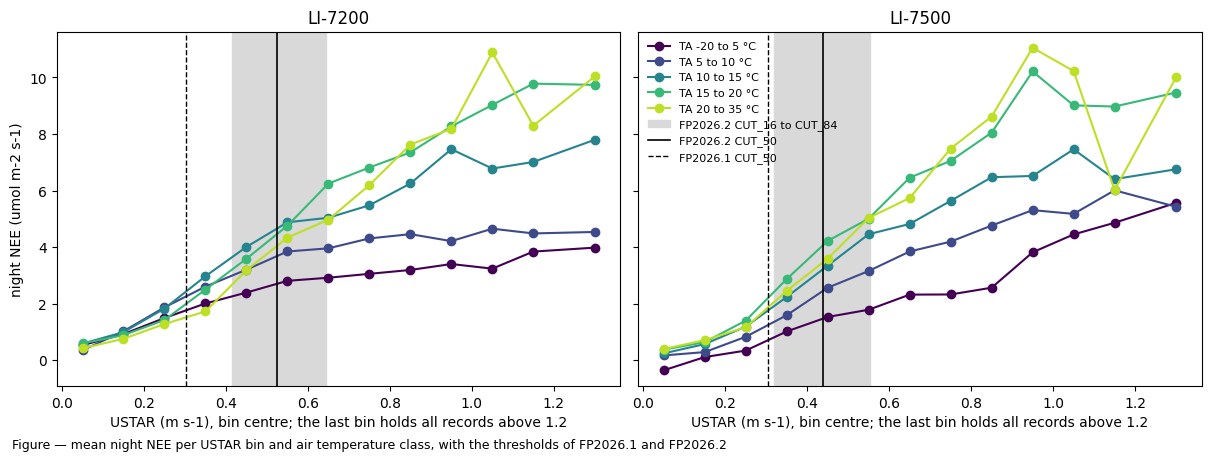

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
_mid = 0.5 * (_ubins[:-1] + _ubins[1:])
_mid[-1] = 1.3
_colors = plt.cm.viridis(np.linspace(0, 0.9, len(_tbins) - 1))
for _ax, _a in zip(axes, data):
    _c = curves[_a]
    for _col, _clr in zip(_c.columns, _colors):
        _ax.plot(_mid[:len(_c)], _c[_col].to_numpy(), marker='o', color=_clr, label=f"TA {_col.left:.0f} to {_col.right:.0f} °C")
    _cut = USTAR_THRESHOLDS[_a]
    _ax.axvspan(_cut[0], _cut[2], color='0.85', zorder=0, label='FP2026.2 CUT_16 to CUT_84')
    _ax.axvline(_cut[1], color='k', lw=1.2, label='FP2026.2 CUT_50')
    _ax.axvline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
    _ax.set_title(ANALYSERS[_a])
    _ax.set_xlabel('USTAR (m s-1), bin centre; the last bin holds all records above 1.2')
axes[0].set_ylabel('night NEE (umol m-2 s-1)')
axes[1].legend(frameon=False, fontsize=8, loc='upper left')
figcap(fig, "mean night NEE per USTAR bin and air temperature class, with the thresholds of FP2026.1 and FP2026.2")
plt.show()

Night `NEE` does not level off at the thresholds. In every temperature class it keeps rising with
`USTAR` up to about 0.9 to 1.0 m s⁻¹, in both analysers, and in the warmest classes beyond. Neither
the thresholds of FP2026.1 nor those of FP2026.2 mark the start of a plateau. Part of the rise may be
real, because wind can draw CO2 out of the soil and the litter. The tower data alone cannot separate
this from flux that is not measured at the tower.

</br>

# 5. Daytime records at low USTAR

REddyProc applies the USTAR filter only at night by default; ONEFlux and this chain apply it by day
too. Daytime records at low `USTAR` would be worth keeping if their `NEE` agreed with that of
well-mixed records under the same conditions. Each daytime record is compared with the mean `NEE`
at `USTAR` above 0.5 m s-1 in its cell: the same month, 50 W m-2 of `SW_IN`, 2 K of `TA` and
quarter of `VPD` (cells with at least 5 such records).

## 📋 Table: daytime NEE at low USTAR against well-mixed records

In [17]:
_parts = {}
for _a, _d in data.items():
    _day = _d[(_d[NIGHTTIME] == 0)].dropna(subset=[NEE, USTAR, VPD, ZL]).copy()
    _vq = pd.qcut(_day[VPD], 4, labels=False)
    _day['cell'] = list(zip((_day[SW_IN] // 50).astype(int), _day.index.month, (_day[TA] // 2).astype(int), _vq))
    _ref = _day[_day[USTAR] > 0.5].groupby('cell')[NEE].agg(['mean', 'size'])
    _day['anom'] = _day[NEE] - _day['cell'].map(_ref['mean'].where(_ref['size'] >= 5))
    _day['group'] = np.where(_day[SW_IN] < 100, 'SW_IN 10-100 (dawn, dusk)',
                             np.where(_day[ZL] < -0.05, 'SW_IN from 100, unstable', 'SW_IN from 100, neutral or stable'))
    _ub = pd.cut(_day[USTAR], [0, 0.1, 0.2, 0.3, 0.4, 0.5, 3])
    _parts[ANALYSERS[_a]] = _day.pivot_table(index=_ub, columns='group', values='anom', aggfunc='mean', observed=True)
day_table = pd.concat(_parts, axis=1)
day_table.index = [f"{i.left:.1f}-{i.right:.1f}" for i in day_table.index]
day_table.index.name = 'USTAR (m s-1)'
day_table.columns = [f"{a}, {g}" for a, g in day_table.columns]
display(styled(day_table, caption="daytime NEE minus the mean NEE at USTAR above 0.5 m s-1 in the same cell "
                                  "(umol m-2 s-1). Positive: less uptake than the well-mixed records; negative: "
                                  "more uptake"))

Table — daytime NEE minus the mean NEE at USTAR above 0.5 m s-1 in the same cell (umol m-2 s-1).
Positive: less uptake than the well-mixed records; negative: more uptake



,"LI-7200, SW_IN 10-100 (dawn, dusk)","LI-7200, SW_IN from 100, neutral or stable","LI-7200, SW_IN from 100, unstable","LI-7500, SW_IN 10-100 (dawn, dusk)","LI-7500, SW_IN from 100, neutral or stable","LI-7500, SW_IN from 100, unstable"
USTAR (m s-1),,,,,,
0.0-0.1,-2.60,4.78,3.56,-2.42,6.29,4.81
0.1-0.2,-2.31,4.32,3.92,-1.84,7.55,4.48
0.2-0.3,-1.87,4.33,3.51,-1.69,5.53,3.68
0.3-0.4,-1.43,3.35,2.16,-1.54,3.98,2.45
0.4-0.5,-0.74,1.76,1.10,-0.58,2.30,1.51
0.5-3.0,-0.00,0.43,-0.16,-0.00,0.24,-0.08


Daytime records at low `USTAR` differ from the well-mixed records under the same conditions. In sun
(`SW_IN` from 100 W m⁻²) they show less uptake, by about 2 to 8 µmol m⁻² s⁻¹ below 0.4 m s⁻¹. At dawn
and dusk they show more uptake, by about 1.4 to 2.6 µmol m⁻² s⁻¹, which is the night-time bias
carried into the twilight. The filter therefore applies by day as well, as in ONEFlux.

</br>

# 6. Records kept and night-time respiration

A higher threshold removes more records. Their number decides how well gap-filling and the
night-time partitioning are constrained.

## 📋 Table: records kept per threshold

In [18]:
_rows = {}
reco = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _night = _d[NIGHTTIME] == 1
    _yr = _d.index.year
    _ok = _d[NEE].notna()
    _thr = {**COMPARE, 'FP2026.2 CUT_16': USTAR_THRESHOLDS[_a][0], 'FP2026.2 CUT_50': USTAR_THRESHOLDS[_a][1],
            'FP2026.2 CUT_84': USTAR_THRESHOLDS[_a][2]}
    _e0 = _d.groupby(_yr)['E0_NT_OF_CUT_50'].median()
    for _lab, _t in sorted(_thr.items(), key=lambda kv: kv[1]):
        _kept = _ok & (_d[USTAR] >= _t)
        _r = reco_estimate(_d, _d[NEE].where(_kept & (_d[SW_IN] < NIGHT_SW_IN)), _e0)
        reco[(_a, _lab)] = _r.groupby(_yr).sum(min_count=1) * GC
        _rows[(ANALYSERS[_a], f"{_lab} ({_t:.2f})")] = {
            'day records per year': _kept[~_night].groupby(_yr[~_night]).sum().mean(),
            'night records per year': _kept[_night].groupby(_yr[_night]).sum().mean(),
            'night measured (%)': _kept[_night].groupby(_yr[_night]).mean().mean() * 100,
            'night measured, lowest year (%)': _kept[_night].groupby(_yr[_night]).mean().min() * 100}
    _rows[(ANALYSERS[_a], 'no USTAR filter')] = {
        'day records per year': _ok[~_night].groupby(_yr[~_night]).sum().mean(),
        'night records per year': _ok[_night].groupby(_yr[_night]).sum().mean(),
        'night measured (%)': _ok[_night].groupby(_yr[_night]).mean().mean() * 100,
        'night measured, lowest year (%)': _ok[_night].groupby(_yr[_night]).mean().min() * 100}
kept_table = pd.DataFrame(_rows).T
display(styled(kept_table, caption="NEE records per complete year after Level 3.2 that pass the USTAR filter at each "
                                   "threshold, by day and by night (night as flagged by the chain), and the share of "
                                   "the night half-hours they cover", fmt={'day records per year': "{:.0f}",
                                   'night records per year': "{:.0f}", 'night measured (%)': "{:.1f}",
                                   'night measured, lowest year (%)': "{:.1f}"}, cmap=None))

Table — NEE records per complete year after Level 3.2 that pass the USTAR filter at each threshold,
by day and by night (night as flagged by the chain), and the share of the night half-hours they
cover



## 📋 Table: night-time respiration per threshold

In [19]:
_rows = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _chain = _d['RECO_NT_OF_CUT_50'].groupby(_d.index.year).sum(min_count=1) * GC
    _base = reco[(_a, 'FP2026.1 CUT_50')]
    _years = _chain.dropna().index
    _rows[(ANALYSERS[_a], 'chain, FP2026.1 CUT_50')] = {'RECO (gC m-2 per year)': _chain[_years].mean(), 'against FP2026.1 CUT_50 (%)': np.nan}
    for (_aa, _lab), _r in reco.items():
        if _aa != _a:
            continue
        _rows[(ANALYSERS[_a], f"estimate, {_lab}")] = {'RECO (gC m-2 per year)': _r[_years].mean(),
                                                       'against FP2026.1 CUT_50 (%)': (_r[_years].mean() / _base[_years].mean() - 1) * 100}
reco_table = pd.DataFrame(_rows).T
display(styled(reco_table, caption="mean annual night-time respiration: the chain's RECO_NT at the FP2026.1 "
                                   "threshold, and a simple estimate for each threshold (reference respiration per "
                                   "day from the measured nights, Lloyd-Taylor with the chain's E0 of the year). The "
                                   "estimate at the FP2026.1 threshold checks the method against the chain; the "
                                   "change is relative to that estimate. E0 is held fixed, so only the level changes",
               fmt={'RECO (gC m-2 per year)': "{:.0f}", 'against FP2026.1 CUT_50 (%)': "{:+.0f}"}, cmap=None))

Table — mean annual night-time respiration: the chain's RECO_NT at the FP2026.1 threshold, and a
simple estimate for each threshold (reference respiration per day from the measured nights, Lloyd-
Taylor with the chain's E0 of the year). The estimate at the FP2026.1 threshold checks the method
against the chain; the change is relative to that estimate. E0 is held fixed, so only the level
changes



Every increase of the threshold costs measured records. At the FP2026.2 median thresholds about 20 %
of the night half-hours stay measured, against 28 to 37 % at the FP2026.1 threshold, and about 15 % in
the poorest year. By day the loss is similar. The night-time respiration estimated from the measured
nights rises with the threshold, by 20 to 27 % at the FP2026.2 median thresholds.

</br>

# 7. Comparison with FLUXNET

FLUXNET (ONEFlux v1.3) detects thresholds per year with the moving point and the change point
methods pooled, and selects one of 40 threshold percentiles as the reference, once for a constant
threshold over all years (`CUT_REF`) and once per year (`VUT_REF`). Until 2015 it uses the LI-7500
with its own self-heating correction, from 2016 the LI-7200. The full comparison of the LI-7500
years is in [`FLUX_NEE_IRGA75_COMPARISONS`](../90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.ipynb).

In [20]:
_bif = pd.read_csv(FLUXNET_DIR / FLUXNET_BIF)
_ref = _bif[_bif['VARIABLE_GROUP'] == 'GRP_FLUX_REF'].pivot_table(index='GROUP_ID', columns='VARIABLE', values='DATAVALUE', aggfunc='first')
_ref = _ref[(_ref['REF_VARIABLE'] == 'NEE') & (_ref['REF_TIME_RESOLUTION'] == 'HH')]
FLX_CUT_REF = float(_ref.loc[_ref['REF_VERSION'] == 'CUT', 'REF_USTAR_THRESHOLD'].iloc[0])
_v = _ref[_ref['REF_VERSION'] == 'VUT']
FLX_VUT_REF = _v.assign(year=_v['REF_YEAR'].astype(int)).groupby('year')['REF_USTAR_THRESHOLD'].first().astype(float)
_yy = pd.read_csv(FLUXNET_DIR / FLUXNET_YY, na_values=FLX_MISSING).set_index('TIMESTAMP')
_hh = pd.read_csv(FLUXNET_DIR / FLUXNET_HH, na_values=FLX_MISSING,
                  usecols=['TIMESTAMP_START', 'NIGHT', 'NEE_CUT_REF', 'NEE_CUT_REF_QC', 'NEE_VUT_REF', 'NEE_VUT_REF_QC'])
_hh.index = pd.to_datetime(_hh.pop('TIMESTAMP_START').astype(str), format='%Y%m%d%H%M') + pd.Timedelta('15min')
flx_hh = _hh
# this product: LI-7500 to 2015, LI-7200 from 2016, at the thresholds of the current chain run
prod_hh = pd.concat([data['IRGA75'].loc[:'2015'], data['IRGA72'].loc['2016':'2024']])
print(f"FLUXNET CUT_REF threshold for half-hourly NEE: {FLX_CUT_REF:.3f} m s-1")

FLUXNET CUT_REF threshold for half-hourly NEE: 0.430 m s-1


## 📋 Table: thresholds of FLUXNET and of this product per year

In [21]:
_mp_vut = pd.concat([detections[('IRGA75', 'oneflux_mp')].get_vut_thresholds()['p50'].loc[:2015],
                     detections[('IRGA72', 'oneflux_mp')].get_vut_thresholds()['p50'].loc[2016:2024]])
flx_thr = pd.DataFrame({'FLUXNET VUT_REF': FLX_VUT_REF, 'FLUXNET CUT_REF': FLX_CUT_REF,
                        'this product, moving point VUT (median)': _mp_vut})
flx_thr['this product, FP2026.2 CUT_50'] = [USTAR_THRESHOLDS['IRGA75'][1] if y <= 2015 else USTAR_THRESHOLDS['IRGA72'][1]
                                           for y in flx_thr.index]
flx_thr['this product, FP2026.1 CUT_50'] = USTAR_THRESHOLDS_FP1[1]
flx_thr.index.name = 'year'
display(styled(flx_thr, caption="USTAR thresholds (m s-1) for half-hourly NEE: the reference thresholds FLUXNET "
                                "selected, per year (VUT_REF) and constant (CUT_REF), and those of this product. "
                                "The analyser is the LI-7500 to 2015 and the LI-7200 from 2016 in both", cmap=None))

Table — USTAR thresholds (m s-1) for half-hourly NEE: the reference thresholds FLUXNET selected, per
year (VUT_REF) and constant (CUT_REF), and those of this product. The analyser is the LI-7500 to
2015 and the LI-7200 from 2016 in both



,FLUXNET VUT_REF,FLUXNET CUT_REF,"this product, moving point VUT (median)","this product, FP2026.2 CUT_50","this product, FP2026.1 CUT_50"
year,,,,,
2004,0.28,0.43,0.44,0.44,0.30
2005,0.26,0.43,0.42,0.44,0.30
2006,0.32,0.43,0.43,0.44,0.30
2007,0.30,0.43,0.49,0.44,0.30
2008,0.29,0.43,0.49,0.44,0.30
2009,0.27,0.43,0.44,0.44,0.30
2010,0.23,0.43,0.41,0.44,0.30
2011,0.24,0.43,0.41,0.44,0.30
2012,0.26,0.43,0.42,0.44,0.30


## 📋 Table: annual NEE and night records of FLUXNET and of this product

In [22]:
_py, _pn = prod_hh.index.year, prod_hh[NIGHTTIME] == 1
_pm = prod_hh['FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'] == 0
_fy, _fn = flx_hh.index.year, flx_hh['NIGHT'] == 1
_fm = flx_hh['NEE_VUT_REF_QC'] == 0
flx_ann = pd.DataFrame({
    'FLUXNET NEE_CUT_REF': _yy['NEE_CUT_REF'], 'FLUXNET NEE_VUT_REF': _yy['NEE_VUT_REF'],
    'this product NEE (CUT_50)': prod_hh['NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py).sum() * GC,
    'FLUXNET VUT_REF night sum': flx_hh.loc[_fn, 'NEE_VUT_REF'].groupby(_fy[_fn]).sum() * GC,
    'this product night sum': prod_hh.loc[_pn, 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py[_pn]).sum() * GC,
    'FLUXNET VUT_REF night measured (%)': _fm[_fn].groupby(_fy[_fn]).mean() * 100,
    'this product night measured (%)': _pm[_pn].groupby(_py[_pn]).mean() * 100,
    'FLUXNET VUT_REF mean measured night NEE': flx_hh.loc[_fn & _fm, 'NEE_VUT_REF'].groupby(_fy[_fn & _fm]).mean(),
    'this product mean measured night NEE': prod_hh.loc[_pn & _pm, 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py[_pn & _pm]).mean(),
}).loc[2005:2024]
flx_ann.index.name = 'year'
_sums = [c for c in flx_ann.columns if 'NEE_' in c or 'NEE (' in c or 'sum' in c]
display(styled(flx_ann, caption="annual NEE in gC m-2 (FLUXNET CUT_REF and VUT_REF from its yearly file, this "
                                "product at the thresholds of its current chain run), the night sums, the share "
                                "of night half-hours measured, and the mean measured night NEE in umol m-2 s-1. "
                                "Each product uses its own night flag. 2004 is left out: FLUXNET starts in March",
               fmt={c: ("{:.0f}" if c in _sums else ("{:.1f}" if '%' in c else "{:.2f}")) for c in flx_ann.columns}, cmap=None))

Table — annual NEE in gC m-2 (FLUXNET CUT_REF and VUT_REF from its yearly file, this product at the
thresholds of its current chain run), the night sums, the share of night half-hours measured, and
the mean measured night NEE in umol m-2 s-1. Each product uses its own night flag. 2004 is left out:
FLUXNET starts in March



,FLUXNET NEE_CUT_REF,FLUXNET NEE_VUT_REF,this product NEE (CUT_50),FLUXNET VUT_REF night sum,this product night sum,FLUXNET VUT_REF night measured (%),this product night measured (%),FLUXNET VUT_REF mean measured night NEE,this product mean measured night NEE
year,,,,,,,,,
2005,60,-158,62,398,562,23.6,26.4,2.53,3.17
2006,-49,-124,43,355,567,22.3,29.8,2.52,3.51
2007,-251,-352,-180,425,603,25.4,32.3,2.78,3.63
2008,-208,-201,-57,441,615,26.0,32.1,2.87,3.85
2009,-227,-270,-57,314,559,24.4,28.4,1.82,3.07
2010,-448,-441,-168,277,494,25.9,27.6,1.99,3.30
2011,-493,-517,-312,443,608,26.2,29.4,2.85,3.76
2012,-492,-680,-338,273,531,21.7,24.6,2.29,3.38
2013,-521,-545,-297,306,533,23.5,28.4,2.06,3.41


## 📋 Table: mean annual NEE per period

In [23]:
_periods = {'2005-2006': (2005, 2006), '2007-2015': (2007, 2015), '2016-2017': (2016, 2017), '2018-2024': (2018, 2024),
            '2005-2024': (2005, 2024)}
flx_period = pd.DataFrame({k: flx_ann.loc[a:b, ['FLUXNET NEE_CUT_REF', 'FLUXNET NEE_VUT_REF', 'this product NEE (CUT_50)',
                                                'FLUXNET VUT_REF night sum', 'this product night sum']].mean()
                           for k, (a, b) in _periods.items()}).T
display(styled(flx_period, caption="mean annual NEE and night sum (gC m-2) per period. Negative NEE is net uptake",
               fmt="{:.0f}", cmap=None))

Table — mean annual NEE and night sum (gC m-2) per period. Negative NEE is net uptake



,FLUXNET NEE_CUT_REF,FLUXNET NEE_VUT_REF,this product NEE (CUT_50),FLUXNET VUT_REF night sum,this product night sum
2005-2006,5,-141,53,376,564
2007-2015,-381,-437,-219,346,565
2016-2017,109,104,-16,868,715
2018-2024,-48,3,-118,830,702
2005-2024,-177,-199,-136,570,628


## 📋 Table: half-hours measured in both products

In [24]:
_j = flx_hh.join(prod_hh[['NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED']], how='inner')
_j = _j[(_j['NEE_VUT_REF_QC'] == 0) & (_j['FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'] == 0)]
_diff = _j['NEE_L3.1_L3.3_CUT_50_QCF_gfXG'] - _j['NEE_VUT_REF']
_period = np.where(_j.index.year <= 2015, '2004-2015 (LI-7500)', '2016-2024 (LI-7200)')
_tod = np.where(_j['NIGHT'] == 1, 'night', 'day')
_g = _diff.groupby([_period, _tod])
flx_common = pd.DataFrame({'half-hours': _g.size(), 'this product minus FLUXNET, mean': _g.mean(),
                           'median': _g.median()})
display(styled(flx_common, caption="NEE of this product minus FLUXNET VUT_REF (umol m-2 s-1) on the half-hours "
                                   "both measured", fmt={'half-hours': "{:.0f}"}, cmap=None))

Table — NEE of this product minus FLUXNET VUT_REF (umol m-2 s-1) on the half-hours both measured



Over 2005-2024 FLUXNET shows more net uptake than this product, but the difference changes sign
between the two analysers.

- **2005-2015, LI-7500: FLUXNET shows more uptake**, in 2007-2015 by about 160 (`CUT_REF`) and 220
  gC m⁻² per year (`VUT_REF`). The difference lies at night. FLUXNET's night sums are about 200 gC m⁻²
  lower, and on the half-hours both measured its night `NEE` is lower by 0.65 µmol m⁻² s⁻¹ on average;
  by day the two agree within 0.2. Its `VUT_REF` thresholds of these years (0.23 to 0.35 m s⁻¹) lie
  close to or below the FP2026.1 threshold, so the USTAR filter is not the cause. The self-heating
  correction of the LI-7500 is the cause
  ([`FLUX_NEE_IRGA75_COMPARISONS`](../90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.ipynb)).
- **2016-2024, LI-7200: FLUXNET shows less uptake.** In 2018-2024 its mean annual `NEE` is +3
  (`VUT_REF`) and -48 gC m⁻² (`CUT_REF`), against -118 here. On the half-hours both measured the two
  agree. The difference comes from the thresholds: with 0.46 to 0.60 m s⁻¹ (`VUT_REF`) only 10 to 19 %
  of FLUXNET's night half-hours stay measured, against 28 to 43 % here. These are the windier nights
  with higher `NEE`, and the gap-filled nights follow them, so FLUXNET's nights are about 130 gC m⁻²
  higher.
- **Within FLUXNET**, `VUT_REF` shows more uptake than `CUT_REF` where its yearly thresholds lie below
  the constant one (to 2015) and less where they lie above it (from 2016): the same dependence on the
  threshold as in sections 4 and 6.

</br>

# 8. Pooling years and seasons

ONEFlux detects the threshold once per calendar year and pools the bootstrap draws afterwards: the
VUT of a year from the year and its two neighbours, the CUT from all years. The detection itself
sees one year of data. Here the data are pooled before the detection, in two ways:

- **several years:** the moving point method runs on the data of 3 or 5 years centred on the year.
  Each season then holds the same months of all these years, so each temperature and `USTAR` class
  has more records;
- **all years, other seasons:** the moving point method runs on all years at once, with calendar
  quarters, with a leaf-off and a leaf-on season, or with one season. This gives one threshold per
  season.

Each detection has 100 bootstrap draws. The annual threshold is the highest season threshold, as in
ONEFlux.

In [25]:
from joblib import Parallel, delayed


def mp_pooled(frame, seasons):
    """Moving point detection on `frame` with `seasons`: main-run season thresholds and bootstrap
    statistics per season and for the annual (highest season) threshold."""
    try:
        _det = UstarMovingPointDetection(frame, season_groups=seasons, bootstrapping_times=POOL_DRAWS,
                                         random_state=DETECTION['random_state'], verbose=0, **DET_COLS)
        _main = _det.detect()['threshold']
        return _main, _det.bootstrap()
    except ValueError:
        return None, None


_tasks = []
for _a, _d in data.items():
    _y0, _y1 = COMPLETE_YEARS[_a]
    for _y in range(_y0, _y1 + 1):
        for _n in POOL_YEARS:
            _h = _n // 2
            _tasks.append(((_a, f'{_n} year' + ('s' if _n > 1 else ''), _y),
                           _d.loc[str(max(_y0, _y - _h)):str(min(_y1, _y + _h))], SEASONS['quarters']))
    for _lab, _s in SEASONS.items():
        _tasks.append(((_a, f'all years, {_lab}', 0), _d.loc[str(_y0):str(_y1)], _s))
_t = time.time()
_res = Parallel(n_jobs=-1)(delayed(mp_pooled)(_f, _s) for _, _f, _s in _tasks)
pooled = {_k: _r for (_k, _, _), _r in zip(_tasks, _res)}
print(f"{len(_tasks)} detections in {time.time() - _t:.0f} s")

78 detections in 6 s


## 📋 Table: annual threshold per year, one year and pooled years

In [26]:
_rows = {}
for (_a, _var, _y), (_main, _boot) in pooled.items():
    if _y and _boot is not None:
        _rows.setdefault((ANALYSERS[_a], _y), {})[f'{_var} pooled' if _var != '1 year' else '1 year'] = _boot.loc['Annual', 'p50']
for _a in data:
    for _y, _v in detections[(_a, 'oneflux_mp')].get_vut_thresholds()['p50'].items():
        if (ANALYSERS[_a], _y) in _rows:
            _rows[(ANALYSERS[_a], _y)]['VUT (ONEFlux)'] = _v
pool_table = pd.DataFrame(_rows).T
display(styled(pool_table, caption="median of the bootstrap draws of the annual USTAR threshold (m s-1), moving point "
                                    "method with calendar quarters, on the data of the year alone and of 3 and 5 years "
                                    "centred on it (shorter at the ends of the record), and the VUT of ONEFlux, which "
                                    "pools the draws of single years", cmap=None))

Table — median of the bootstrap draws of the annual USTAR threshold (m s-1), moving point method
with calendar quarters, on the data of the year alone and of 3 and 5 years centred on it (shorter at
the ends of the record), and the VUT of ONEFlux, which pools the draws of single years



## 📋 Table: change from year to year against the bootstrap spread

In [27]:
_rows = {}
for _a in data:
    for _var in ('1 year', '3 years', '5 years'):
        _b = [r[1] for (a, v, y), r in pooled.items() if a == _a and v == _var and y and r[1] is not None]
        _med = np.array([b.loc['Annual', 'p50'] for b in _b])
        _sd = np.array([b.loc['Annual', 'std'] for b in _b])
        _rows[(ANALYSERS[_a], _var)] = {'lowest year': _med.min(), 'highest year': _med.max(),
                                        'sd between years': _med.std(ddof=1), 'bootstrap sd within a year': _sd.mean(),
                                        'ratio': _med.std(ddof=1) / _sd.mean()}
spread_table = pd.DataFrame(_rows).T
display(styled(spread_table, caption="spread of the annual thresholds (m s-1) between years, against the mean "
                                      "standard deviation of the bootstrap draws within a year. A ratio below 1 means "
                                      "the years differ by no more than the sampling noise of one year", cmap=None))

Table — spread of the annual thresholds (m s-1) between years, against the mean standard deviation
of the bootstrap draws within a year. A ratio below 1 means the years differ by no more than the
sampling noise of one year



## 📊 Plot: annual threshold per year with the data of one, three and five years

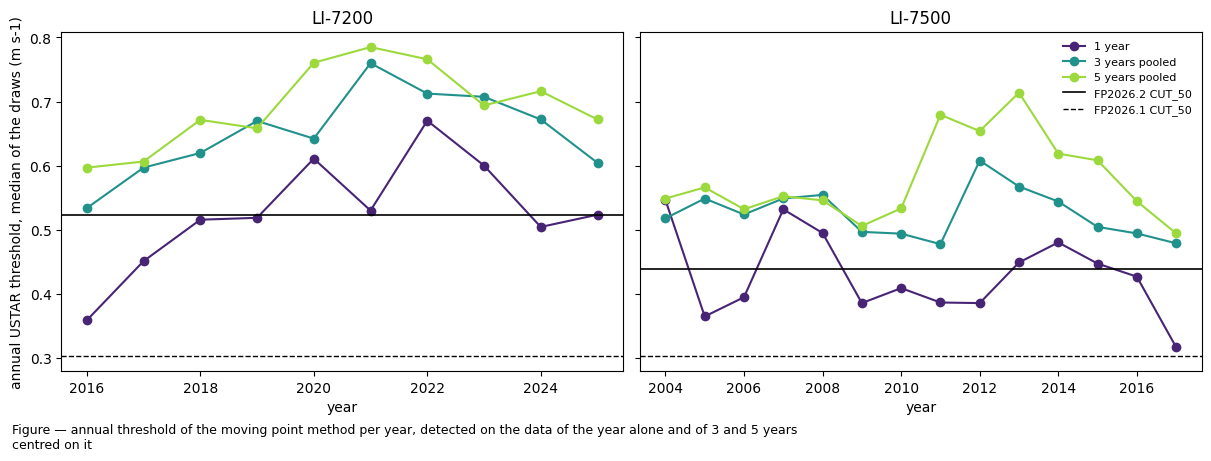

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
for _ax, _a in zip(axes, data):
    _t = pool_table.loc[ANALYSERS[_a]]
    for _col, _clr in zip(['1 year', '3 years pooled', '5 years pooled'], plt.cm.viridis([0.1, 0.5, 0.85])):
        _ax.plot(_t.index, _t[_col], marker='o', color=_clr, label=_col)
    _ax.axhline(USTAR_THRESHOLDS[_a][1], color='k', lw=1.2, label='FP2026.2 CUT_50')
    _ax.axhline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
    _ax.set_title(ANALYSERS[_a])
    _ax.set_xlabel('year')
axes[0].set_ylabel('annual USTAR threshold, median of the draws (m s-1)')
axes[1].legend(frameon=False, fontsize=8)
figcap(fig, "annual threshold of the moving point method per year, detected on the data of the year alone and of "
            "3 and 5 years centred on it")
plt.show()

## 📋 Table: thresholds per season with all years pooled

In [29]:
_rows = {}
for (_a, _var, _y), (_main, _boot) in pooled.items():
    if _y:
        continue
    _lab = _var.replace('all years, ', '')
    for _i, _months in enumerate(SEASONS[_lab]):
        _s = f'Season {_i + 1}'
        _rows[(ANALYSERS[_a], _lab, f"{_s}: months {','.join(map(str, _months))}")] = {
            'main run': _main[_s] if _main is not None else np.nan,
            'draws, median': _boot.loc[_s, 'p50'] if _boot is not None else np.nan,
            'draws, p05': _boot.loc[_s, 'p05'] if _boot is not None else np.nan,
            'draws, p95': _boot.loc[_s, 'p95'] if _boot is not None else np.nan}
    if _boot is not None:
        _rows[(ANALYSERS[_a], _lab, 'annual, highest season')] = {
            'main run': np.nanmax(_main.to_numpy()) if _main.notna().any() else np.nan,
            'draws, median': _boot.loc['Annual', 'p50'], 'draws, p05': _boot.loc['Annual', 'p05'],
            'draws, p95': _boot.loc['Annual', 'p95']}
season_table = pd.DataFrame(_rows).T
display(styled(season_table, caption="USTAR thresholds (m s-1) of the moving point method on all complete years at "
                                      "once, per season, from the main run (empty where it finds no plateau) and from "
                                      "the draws that found one", cmap=None))

Table — USTAR thresholds (m s-1) of the moving point method on all complete years at once, per
season, from the main run (empty where it finds no plateau) and from the draws that found one



## 📋 Table: records kept and night-time respiration per pooling

In [30]:
_rows = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _yr, _mo = _d.index.year, _d.index.month
    _night = _d[NIGHTTIME] == 1
    _ok = _d[NEE].notna()
    _e0 = _d.groupby(_yr)['E0_NT_OF_CUT_50'].median()
    _thr = {'FP2026.1 CUT_50': pd.Series(USTAR_THRESHOLDS_FP1[1], index=_d.index),
            'FP2026.2 CUT_50': pd.Series(USTAR_THRESHOLDS[_a][1], index=_d.index)}
    for _var in ('1 year', '3 years', '5 years'):
        _per_year = {y: r[1].loc['Annual', 'p50'] for (a, v, y), r in pooled.items() if a == _a and v == _var and y}
        _thr[f'{_var}, per year'] = pd.Series(_yr.map(_per_year), index=_d.index)
    for _lab, _s in SEASONS.items():
        _boot = pooled[(_a, f'all years, {_lab}', 0)][1]
        _by_month = {m: _boot.loc[f'Season {i + 1}', 'p50'] for i, g in enumerate(_s) for m in g}
        _thr[f'all years, {_lab}, per season'] = pd.Series(_mo.map(_by_month), index=_d.index)
    _base = None
    for _lab, _t in _thr.items():
        _kept = _ok & (_d[USTAR] >= _t)
        _r = (reco_estimate(_d, _d[NEE].where(_kept & (_d[SW_IN] < NIGHT_SW_IN)), _e0).groupby(_yr).sum(min_count=1) * GC).mean()
        _base = _r if _lab == 'FP2026.2 CUT_50' else _base
        _rows[(ANALYSERS[_a], _lab)] = {'mean threshold': _t[_night].mean(),
                                        'night measured (%)': _kept[_night].groupby(_yr[_night]).mean().mean() * 100,
                                        'RECO (gC m-2 per year)': _r}
    for _k in [k for k in _rows if k[0] == ANALYSERS[_a]]:
        _rows[_k]['against FP2026.2 CUT_50 (%)'] = (_rows[_k]['RECO (gC m-2 per year)'] / _base - 1) * 100
pool_effect = pd.DataFrame(_rows).T
display(styled(pool_effect, caption="mean threshold at night (m s-1), share of the night half-hours that stay measured, "
                                     "and the night-time respiration estimated as in section 6, for each way of pooling. "
                                     "Per-season thresholds apply to the months of their season",
               fmt={'mean threshold': "{:.2f}", 'night measured (%)': "{:.1f}", 'RECO (gC m-2 per year)': "{:.0f}",
                    'against FP2026.2 CUT_50 (%)': "{:+.0f}"}, cmap=None))

Table — mean threshold at night (m s-1), share of the night half-hours that stay measured, and the
night-time respiration estimated as in section 6, for each way of pooling. Per-season thresholds
apply to the months of their season



The thresholds of single years differ by no more than the bootstrap spread within one year, for both
analysers. The threshold therefore stays constant, one value per analyser; a VUT would add scatter
from year to year without a detectable change behind it.

Pooling the data of more years raises the threshold. With all years pooled, the main run finds no
plateau from April to September, and only some of the draws find one: with enough records per class
the plateau test does not pass in summer. The thresholds of single years are low partly because the
class means of one year are noisy enough to pass the plateau test early, as in the synthetic test of
section 3. A threshold from pooled years is therefore not better defined, only higher, and it moves
further as more data are added.

Pooling across seasons (leaf-off and leaf-on, or one season) puts records of different seasons into
the same temperature class. For the LI-7200 this gives 0.73 to 0.80 m s⁻¹. For the LI-7500 the main
run with one season finds no threshold, and the draws that find one give 0.13 m s⁻¹, below the
threshold of every single year. The thresholds per quarter differ between the two analysers and do
not show a common seasonal pattern. Neither gives a usable seasonal threshold.

</br>

# 9. Night NEE against the respiration of the daytime partitioning

The daytime partitioning of the chain (Lasslop et al. 2010, `RECO_DT_OF_CUT_50`) estimates respiration
from the daytime light response, when turbulence is strong. It gives a reference for night `NEE` that
does not depend on the night-time `USTAR` filter, although its temperature sensitivity comes from
night records. If night `NEE` were only too low at weak turbulence, it would rise towards this
reference and stay there.

`RECO_DT_OF_CUT_50` in the current outputs of the chain was computed with the thresholds of FP2026.1.

## 📋 Table: night NEE against RECO_DT by USTAR

In [31]:
_ubins = [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0, 1.2, 3]
_rows = {}
dt_ratio = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _n = _d[(_d[SW_IN] < NIGHT_SW_IN)].dropna(subset=[NEE, RECO_DT, USTAR])
    _season = np.where(_n.index.month.isin(LEAF_ON), 'May-Oct', 'Nov-Apr')
    _g = _n.groupby([_season, pd.cut(_n[USTAR], _ubins)], observed=True)
    _t = pd.DataFrame({'n': _g.size(), 'NEE': _g[NEE].mean(), 'RECO_DT': _g[RECO_DT].mean()})
    _t['NEE / RECO_DT'] = _t['NEE'] / _t['RECO_DT']
    dt_ratio[_a] = _t
    for (_s, _b), _r in _t.iterrows():
        _rows[(ANALYSERS[_a], _s, f"{_b.left:.1f}-{_b.right:.1f}")] = _r
dt_table = pd.DataFrame(_rows).T
display(styled(dt_table, caption="mean night NEE and mean RECO_DT of the same half-hours (umol m-2 s-1) per USTAR "
                                  "class, before the USTAR filter, and their ratio, for May to October and November "
                                  "to April", fmt={'n': "{:.0f}"}, cmap=None))

Table — mean night NEE and mean RECO_DT of the same half-hours (umol m-2 s-1) per USTAR class,
before the USTAR filter, and their ratio, for May to October and November to April



## 📊 Plot: night NEE relative to RECO_DT by USTAR

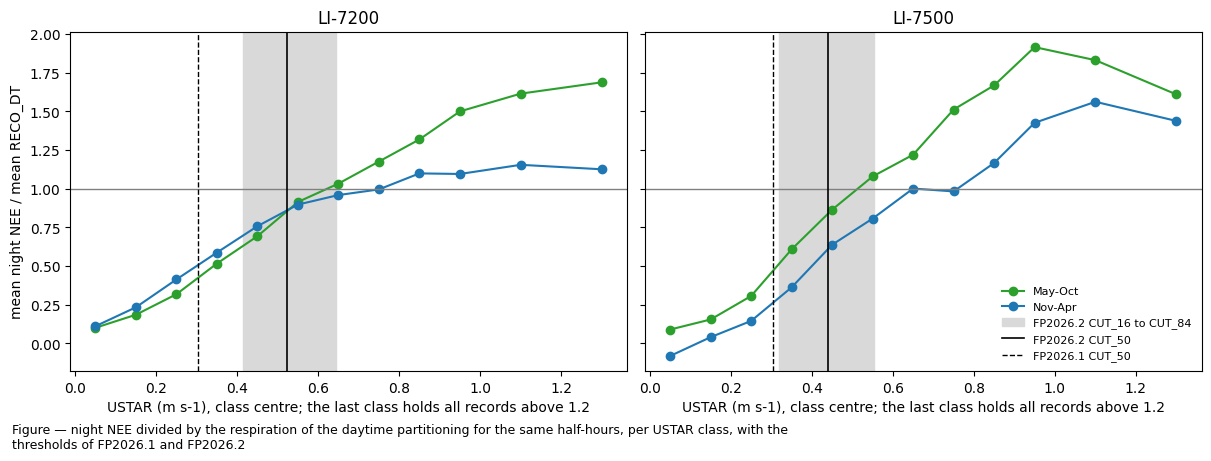

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
for _ax, _a in zip(axes, data):
    for _s, _clr in zip(('May-Oct', 'Nov-Apr'), ('tab:green', 'tab:blue')):
        _t = dt_ratio[_a].loc[_s]
        _mid = [min(b.mid, 1.3) for b in _t.index]
        _ax.plot(_mid, _t['NEE / RECO_DT'], marker='o', color=_clr, label=_s)
    _ax.axhline(1, color='0.5', lw=1)
    _cut = USTAR_THRESHOLDS[_a]
    _ax.axvspan(_cut[0], _cut[2], color='0.85', zorder=0, label='FP2026.2 CUT_16 to CUT_84')
    _ax.axvline(_cut[1], color='k', lw=1.2, label='FP2026.2 CUT_50')
    _ax.axvline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
    _ax.set_title(ANALYSERS[_a])
    _ax.set_xlabel('USTAR (m s-1), class centre; the last class holds all records above 1.2')
axes[0].set_ylabel('mean night NEE / mean RECO_DT')
axes[1].legend(frameon=False, fontsize=8)
figcap(fig, "night NEE divided by the respiration of the daytime partitioning for the same half-hours, per USTAR "
            "class, with the thresholds of FP2026.1 and FP2026.2")
plt.show()

## 📋 Table: kept nights against RECO_DT per threshold

In [33]:
_rows = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _n = _d[(_d[SW_IN] < NIGHT_SW_IN)].dropna(subset=[NEE, RECO_DT, USTAR])
    _thr = {'FP2026.1 CUT_50': USTAR_THRESHOLDS_FP1[1], 'FP2026.2 CUT_16': USTAR_THRESHOLDS[_a][0],
            'FP2026.2 CUT_50': USTAR_THRESHOLDS[_a][1], 'FP2026.2 CUT_84': USTAR_THRESHOLDS[_a][2]}
    _grid = np.round(np.arange(0.20, 1.001, 0.01), 2)
    _ratio = pd.Series([_n.loc[_n[USTAR] >= u, NEE].mean() / _n.loc[_n[USTAR] >= u, RECO_DT].mean() for u in _grid],
                       index=_grid)
    _equal = float(_ratio.index[np.argmax(_ratio.to_numpy() >= 1)]) if (_ratio >= 1).any() else np.nan
    for _lab, _t in {**_thr, 'kept nights equal RECO_DT': _equal}.items():
        _k = _n[_n[USTAR] >= _t]
        _rows[(ANALYSERS[_a], _lab)] = {'threshold': _t, 'night records kept (%)': len(_k) / len(_n) * 100,
                                        'mean NEE / mean RECO_DT': _k[NEE].mean() / _k[RECO_DT].mean()}
dt_thr_table = pd.DataFrame(_rows).T
display(styled(dt_thr_table, caption="mean night NEE of the records at or above each threshold, divided by the mean "
                                      "RECO_DT of the same records; the last row of each analyser is the lowest "
                                      "threshold at which the two are equal",
               fmt={'threshold': "{:.2f}", 'night records kept (%)': "{:.1f}", 'mean NEE / mean RECO_DT': "{:.2f}"},
               cmap=None))

Table — mean night NEE of the records at or above each threshold, divided by the mean RECO_DT of the
same records; the last row of each analyser is the lowest threshold at which the two are equal



Night `NEE` rises to the respiration of the daytime partitioning at a `USTAR` of about 0.5 to
0.8 m s⁻¹ and does not stop there: above it, it exceeds `RECO_DT`, from May to October by up to about
70 % (LI-7200) and 90 % (LI-7500). At the FP2026.2 median thresholds the nights that are kept lie
11 % (LI-7200) and 16 % (LI-7500) above `RECO_DT` on average. The two agree at 0.41 and 0.33 m s⁻¹,
close to `CUT_16`. A threshold higher than that of FP2026.2 would move night `NEE` further above the
daytime reference.

The comparison does not decide which estimate is right. `RECO_DT` depends on the light-response model
and on a temperature sensitivity from night records, and night `NEE` at high `USTAR` may include CO2
released from the canopy air (section 10).

</br>

# 10. Night NEE at high USTAR after calm hours

When the wind rises after calm hours, CO2 that has collected in the canopy air is flushed out and
passes the sensor. The storage term accounts for this only as far as the concentration at the
measurement height shows it. If flushing contributes to the high night `NEE` at high `USTAR`, the
excess over `RECO_DT` should be larger after calm hours than after windy ones.

## 📋 Table: night NEE at high USTAR by the USTAR of the previous hours

In [34]:
_rows = {}
for _a, _d in data.items():
    _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
    _prev = _d[USTAR].shift(1).rolling(2 * PREVIOUS_HOURS, min_periods=PREVIOUS_HOURS + 1).mean()
    _n = _d.assign(prev=_prev)
    _n = _n[(_n[SW_IN] < NIGHT_SW_IN) & (_n[USTAR] > 0.5)].dropna(subset=[NEE, RECO_DT, USTAR, 'prev'])
    _now = pd.cut(_n[USTAR], [0.5, 0.7, 0.9, 3], labels=['0.5-0.7', '0.7-0.9', 'above 0.9'])
    _before = pd.cut(_n['prev'], [0, 0.3, 0.5, 0.7, 3], labels=['below 0.3', '0.3-0.5', '0.5-0.7', 'above 0.7'])
    _g = _n.groupby([_now, _before], observed=True)
    for (_u, _b), _x in _g:
        _rows[(ANALYSERS[_a], _u, _b)] = {'n': len(_x), 'NEE - RECO_DT': (_x[NEE] - _x[RECO_DT]).mean(),
                                         'NEE / RECO_DT': _x[NEE].mean() / _x[RECO_DT].mean(),
                                         'storage term': _x[STORAGE].mean()}
flush_table = pd.DataFrame(_rows).T
display(styled(flush_table, caption=f"night records with USTAR above 0.5 m s-1, by their USTAR (first level) and the "
                                     f"mean USTAR of the previous {PREVIOUS_HOURS} hours (second level): mean NEE minus "
                                     f"RECO_DT and their ratio, and the mean storage term of the chain (umol m-2 s-1)",
               fmt={'n': "{:.0f}"}, cmap=None))

Table — night records with USTAR above 0.5 m s-1, by their USTAR (first level) and the mean USTAR of
the previous 3 hours (second level): mean NEE minus RECO_DT and their ratio, and the mean storage
term of the chain (umol m-2 s-1)



At the same `USTAR`, night `NEE` exceeds `RECO_DT` more when the previous hours were calm, most
clearly above 0.9 m s⁻¹. These cases are few. The storage term is not clearly negative in them,
although CO2 leaving the canopy air should make it negative: the concentration at one height does
not capture the release. Part of the high night `NEE` at high `USTAR` is therefore CO2 that collected during the
calm hours before. After several windy hours an excess over `RECO_DT` remains, which flushing does
not explain.

</br>

# Conclusion and open points

**Decided for FP2026.2**

- The USTAR thresholds come from the ONEFlux moving point method, one set per analyser. They are
  used as constant thresholds (`CUT_16`, `CUT_50`, `CUT_84`) and written as fixed values into the
  chain notebooks. This notebook checks them against a new detection after each rerun of Level 3.2.
- The moving point method is chosen because, of the methods that detect a threshold at this site, it
  gives the lowest one. The aim is to keep as many records as can be defended.
- The filter applies by day and by night.
- One constant set of thresholds per analyser: the thresholds of single years differ by no more
  than their bootstrap spread. Pooling years or seasons before the detection is not used, because
  it raises the threshold or makes the detection fail, without a plateau to define it.

**Open**

- Night `NEE` still rises above the thresholds. Whether this is flux the tower misses or efflux drawn
  out by wind is not resolved; independent respiration data would help to decide. At the FP2026.2 thresholds the measured nights
  lie above the respiration of the daytime partitioning, and part of the excess at high `USTAR` is
  CO2 flushed from the canopy air, which the storage term from one height does not capture.
- The thresholds rest on Level 3.2 of the chain runs listed under Load data. After a rerun of Level
  3.2 the check in section 2 shows whether they still hold.

</br>

# End of notebook

In [35]:
_dt = datetime.now() - NOTEBOOK_START
print(f"Finished {datetime.now():%Y-%m-%d %H:%M:%S}; runtime {_dt.total_seconds() / 60:.1f} min")

Finished 2026-11-01 13:36:17; runtime 1.2 min
